In [11]:
import os
for path in [os.path.join("..", "results", "graphs"),
             os.path.join("..", "results", "tables"),
             os.path.join("..", "results", "experiment_outputs"),
             os.path.join("..", "data", "raw"),
             os.path.join("..", "data", "processed")]:
    print(path, "| exists:", os.path.exists(path),
          "| is folder:", os.path.isdir(path),
          "| is file:", os.path.isfile(path))

..\results\graphs | exists: True | is folder: False | is file: True
..\results\tables | exists: True | is folder: True | is file: False
..\results\experiment_outputs | exists: False | is folder: False | is file: False
..\data\raw | exists: True | is folder: True | is file: False
..\data\processed | exists: True | is folder: True | is file: False


In [22]:
preview = []
for q in [100, 110, 120, 130, 140]:
    m, s_err = expected_profit(q, demand, **COSTS)
    preview.append({"Q": q, "expected_profit": round(float(m)), "std_error": round(float(s_err), 1)})
pd.DataFrame(preview)

,Q,expected_profit,std_error
0,100,65778,22.7
1,110,73156,43.1
2,120,76196,94.8
3,130,73090,144.3
4,140,65758,167.9


## Module 07 summary
- Verified the profit function against hand calculations (Q = 120; D = 100, 120, 130).
- For Q = 120 on 10,000 Poisson(120) scenarios, expected profit ≈ ₹76,196 (SE ₹94.8, 95% interval ₹76,010 to ₹76,381).
- Individual scenario profits ranged from ₹20,000 to ₹84,000, so expected profit is an average, not what happens in any one period.
- Standard error fell from 911.7 to 304.5 to 94.8 as N grew from 100 to 1,000 to 10,000, roughly a factor of √10 each time.
- A preview of Q = 100 to 140 shows expected profit peaking near Q = 120. The full search over 0 to 500 is done in Module 08.
- All parameter values are illustrative assumptions and the demand is synthetic.


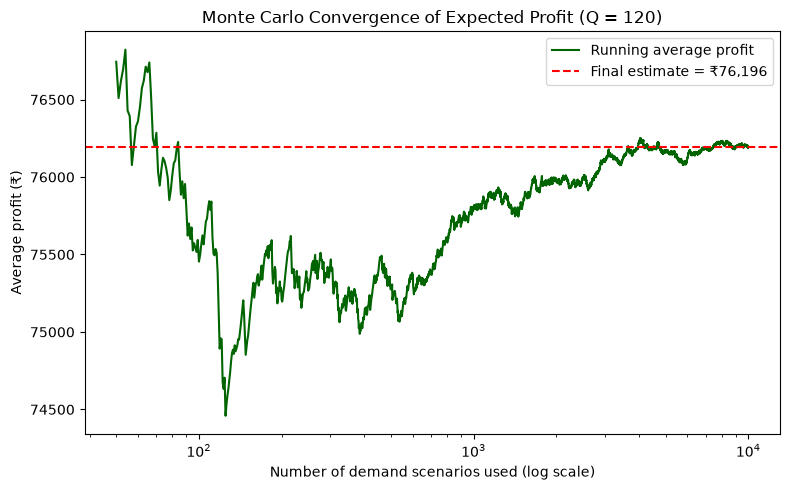

In [21]:
Q = 120
rm = running_mean(Q, demand, **COSTS)
n_axis = np.arange(1, len(rm) + 1)

plt.figure(figsize=(8, 5))
plt.plot(n_axis[49:], rm[49:], color="darkgreen", label="Running average profit")
plt.axhline(rm[-1], color="red", linestyle="--", label=f"Final estimate = ₹{rm[-1]:,.0f}")
plt.xscale("log")
plt.title(f"Monte Carlo Convergence of Expected Profit (Q = {Q})")
plt.xlabel("Number of demand scenarios used (log scale)")
plt.ylabel("Average profit (₹)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "02_convergence_Q120.png"), dpi=200)
plt.show()

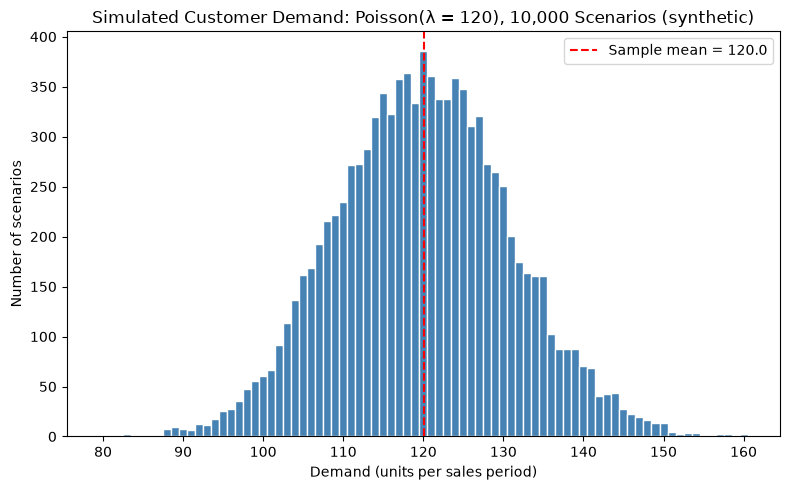

In [20]:
plt.figure(figsize=(8, 5))
plt.hist(demand, bins=np.arange(demand.min(), demand.max() + 2) - 0.5,
         color="steelblue", edgecolor="white")
plt.axvline(demand.mean(), color="red", linestyle="--",
            label=f"Sample mean = {demand.mean():.1f}")
plt.title("Simulated Customer Demand: Poisson(λ = 120), 10,000 Scenarios (synthetic)")
plt.xlabel("Demand (units per sales period)")
plt.ylabel("Number of scenarios")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "01_demand_histogram.png"), dpi=200)
plt.show()

In [19]:
Q = 120
rows = []
for n in [100, 1_000, 10_000]:
    m, s_err = expected_profit(Q, demand[:n], **COSTS)
    rows.append({"N": n, "estimate": round(float(m)), "std_error": round(float(s_err), 1)})
pd.DataFrame(rows)

,N,estimate,std_error
0,100,75454,911.7
1,1000,75811,304.5
2,10000,76196,94.8


In [18]:
Q = 120
mean, se = expected_profit(Q, demand, **COSTS)
print(f"Expected profit at Q={Q}: ₹{mean:,.0f}")
print(f"Standard error          : ₹{se:,.1f}")
print(f"Approx. 95% interval    : ₹{mean - 1.96*se:,.0f} to ₹{mean + 1.96*se:,.0f}")

Expected profit at Q=120: ₹76,196
Standard error          : ₹94.8
Approx. 95% interval    : ₹76,010 to ₹76,381


In [17]:
Q = 120
profits = profit(Q, demand, **COSTS)

print("First 5 demands :", demand[:5])
print("First 5 profits :", profits[:5])
print(f"Lowest scenario profit : {profits.min():,.0f}")
print(f"Highest scenario profit: {profits.max():,.0f}")
print(f"Average profit (expected profit estimate): {profits.mean():,.0f}")

First 5 demands : [129 134 129 105 116]
First 5 profits : [82200 81200 82200 60000 77600]
Lowest scenario profit : 20,000
Highest scenario profit: 84,000
Average profit (expected profit estimate): 76,196


In [16]:
# Hand calculations with Q = 120
# D=100: 1500*100 - 800*120 - 100*20 = 150000 - 96000 - 2000 = 52000
# D=120: 1500*120 - 800*120          = 180000 - 96000        = 84000
# D=130: 1500*120 - 800*120 - 200*10 = 180000 - 96000 - 2000 = 82000
assert profit(120, 100, **COSTS) == 52000
assert profit(120, 120, **COSTS) == 84000
assert profit(120, 130, **COSTS) == 82000
print("Profit function matches the hand calculations.")

Profit function matches the hand calculations.


In [15]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))
from src.profit import profit
from src.simulation import expected_profit, running_mean

COSTS = dict(p=1500, c=800, h=100, s=200)   # illustrative assumptions
GRAPHS_DIR = os.path.join("..", "results", "graphs")
os.makedirs(GRAPHS_DIR, exist_ok=True)

df = pd.read_csv(os.path.join("..", "data", "processed", "synthetic_demand_clean.csv"))
demand = df["poisson"].to_numpy()          # base case: Poisson(120)
Q = 120
print("Scenarios:", len(demand), "| mean demand:", demand.mean().round(2))

Scenarios: 10000 | mean demand: 120.02


In [15]:
import sys, os
sys.path.append(os.path.abspath(".."))
import src.profit
print(src.profit.__file__)
print([name for name in dir(src.profit) if not name.startswith("_")])

c:\Users\vishw\Desktop\E-com\src\profit.py
['np', 'profit']


In [11]:
import os
path = os.path.join("..", "src", "profit.py")
print(os.path.abspath(path))
print("size in bytes:", os.path.getsize(path))
print("-----")
print(open(path, encoding="utf-8").read())

c:\Users\vishw\Desktop\E-com\src\profit.py
size in bytes: 536
-----
import numpy as np


def profit(Q, D, p=1500, c=800, h=100, s=200):
    """
    Profit for order quantity Q and demand D (works for single numbers or arrays).

    p: selling price, c: purchase cost, h: holding cost per unsold unit,
    s: shortage penalty per unmet unit (an extra penalty, NOT lost revenue).
    """
    Q = np.asarray(Q)
    D = np.asarray(D)
    units_sold = np.minimum(Q, D)
    unsold = np.maximum(Q - D, 0)
    unmet = np.maximum(D - Q, 0)
    return p * units_sold - c * Q - h * unsold - s * unmet
